# Magnetic ordering

Magnetic ordering adds a term to G that depends on composition. In the
Inden–Hillert–Jarl (IHJ) model it is

$$G_\mathrm{mag} = RT \ln(\beta + 1)\, f(\tau), \qquad \tau = T / T_C,$$

where T_C(y) and β(y) (the moment in Bohr magnetons) are Redlich–Kister sums
like any other parameter. f is a polynomial with one branch on each side of
τ = 1. Negative T_C and β mark antiferromagnetism and are divided by the AFM
factor (−1 for BCC, −3 for FCC). Xiong et al. revised f and separated T_C from
the Néel temperature T_N; `discopt-calphad` implements both.

For certification, the term must be bounded over any box of site fractions.
T_C(y) can cross T inside a box, so pricing splits a magnetic phase into the
branches (signs of T_C and β, and τ < 1 or ≥ 1) that an interval evaluation
cannot rule out, and bounds each branch globally.

References for comparison:

- A. T. Dinsdale, *SGTE data for pure elements*, Calphad 15 (1991) 317–425:
  transition temperatures of pure Fe;
- G. Inden, Proc. CALPHAD V (1976) III.4; M. Hillert and M. Jarl, Calphad 2
  (1978) 227–238: the IHJ model;
- J.-O. Andersson and B. Sundman, *Thermodynamic properties of the Cr–Fe
  system*, Calphad 11 (1987) 83–92: the Cr–Fe description used here;
- E. Fawcett, *Spin-density-wave antiferromagnetism in chromium*, Rev. Mod.
  Phys. 60 (1988) 209–283: the Néel temperature of Cr, 311 K;
- W. Xiong, Q. Chen, P. A. Korzhavyi and M. Selleby, *An improved magnetic
  model for thermodynamic modeling*, Calphad 39 (2012) 11–20.

In [1]:
import dataclasses

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import brentq

from discopt.calphad import databases, equilibrium
from discopt.calphad.equilibrium.common import R_GAS
from discopt.calphad.models.magnetic import Magnetic, ihj, xiong
from discopt.calphad.ops import NUM

db = databases.load("crfenb_jacob")  # A. Jacob (2016); Cr–Fe from Andersson and Sundman (1987)
models = db.phase_models(("CR", "FE"))
bcc, fcc, liq = models["BCC_A2"], models["FCC_A1"], models["LIQUID"]
print({name: type(p).__name__ + (" (magnetic)" if getattr(p, "magnetic", None) else "") for name, p in models.items()})

{'BCC_A2': 'CEFPhase (magnetic)', 'FCC_A1': 'CEFPhase (magnetic)', 'LIQUID': 'BinarySolution', 'LAVES_C14': 'CEFPhase', 'LAVES_C15': 'CEFPhase', 'SIGMA': 'BinarySolution'}


## Pure iron: magnetism makes α-Fe stable

Pure Fe is the Fe end of the Cr–Fe models (exact, since 0 ln 0 = 0). The
crossings of G(BCC), G(FCC) and G(liquid) give the α → γ → δ sequence and
melting. Compare them with the SGTE values, then remove the magnetic term.

In [2]:
def pure_fe(phase):
    if not hasattr(phase, "constituents"):  # a BinarySolution: y is the fraction of its first element
        return np.array([float(phase.elements[0] == "FE")])
    return phase.variables_from_site_fractions(
        [{c: float(c == "FE") if "FE" in cons else 1.0 for c in cons} for cons in phase.constituents]
    )


def G(phase, T):
    """G of pure Fe in ``phase``, J/mol."""
    return float(phase.gibbs(pure_fe(phase), NUM, T)) * R_GAS * T


def crossing(p, q, lo, hi):
    d = lambda T: G(p, T) - G(q, T)  # noqa: E731
    return brentq(d, lo, hi, xtol=1e-6) if d(lo) * d(hi) < 0 else None


nb, nf = dataclasses.replace(bcc, magnetic=None), dataclasses.replace(fcc, magnetic=None)
sgte = {"α → γ": 1184.81, "γ → δ": 1667.47, "melting": 1811.00}
windows = {"α → γ": (900.0, 1400.0, "fcc"), "γ → δ": (1400.0, 1780.0, "fcc"), "melting": (1700.0, 1900.0, "liq")}
print(f"{'transition':10s} {'SGTE':>9s} {'with magnetism':>15s} {'without':>10s}")
for name, (lo, hi, other) in windows.items():
    w = crossing(bcc, fcc if other == "fcc" else liq, lo, hi)
    wo = crossing(nb, nf if other == "fcc" else liq, lo, hi)
    print(f"{name:10s} {sgte[name]:9.2f} {w:15.2f} {'none' if wo is None else f'{wo:10.2f}'}")

transition      SGTE  with magnetism    without
α → γ        1184.81         1184.81 none
γ → δ        1667.47         1667.47 none
melting      1811.00         1810.95    1801.34


With magnetism the crossings match the SGTE transitions. Without it, FCC is
below BCC at room temperature, and the α → γ transition disappears. The heat
capacity C_p = −T ∂²G/∂T² shows the λ peak at the Curie temperature
(T_C = 1043 K):

C_p of BCC Fe peaks at 1042 K


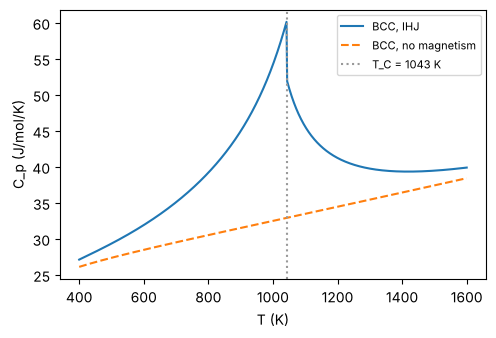

In [3]:
def cp(phase, T, h=0.05):
    return -T * (G(phase, T + h) - 2 * G(phase, T) + G(phase, T - h)) / h**2


Ts = np.linspace(400.0, 1600.0, 1201)
cp_bcc = np.array([cp(bcc, T) for T in Ts])
print(f"C_p of BCC Fe peaks at {Ts[np.argmax(cp_bcc)]:.0f} K")

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(Ts, cp_bcc, label="BCC, IHJ")
ax.plot(Ts, [cp(nb, T) for T in Ts], "--", label="BCC, no magnetism")
ax.axvline(1043, color="0.6", ls=":", label="T_C = 1043 K")
ax.set_xlabel("T (K)")
ax.set_ylabel("C_p (J/mol/K)")
ax.legend(fontsize=8)
plt.show()

## Cr–Fe: ferromagnetic Fe, antiferromagnetic Cr

In BCC Cr–Fe, T_C runs from 1043 K (Fe) down to the Néel temperature of Cr,
entered as T_C = −311.5 K and divided by the AFM factor −1. The experimental
Néel temperature of Cr is 311 K (Fawcett 1988).

T_C(Fe) = 1043.0 K;  T_N(Cr) = 311.5 K


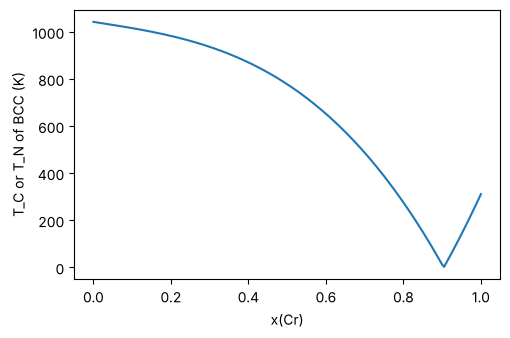

In [4]:
xg = np.linspace(0, 1, 201)
yv = [bcc.variables_from_site_fractions([{"CR": x, "FE": 1 - x}, {"VA": 1.0}]) for x in xg]
tc = np.array([bcc.curie_temperature(u, 300.0) for u in yv])
print(f"T_C(Fe) = {tc[0]:.1f} K;  T_N(Cr) = {tc[-1] / bcc.magnetic.afm:.1f} K")
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(xg, np.where(tc > 0, tc, tc / bcc.magnetic.afm))
ax.set_xlabel("x(Cr)")
ax.set_ylabel("T_C or T_N of BCC (K)")
plt.show()

### The γ loop

Cr stabilizes BCC, so FCC exists only in a loop on the Fe side. The Cr content
of FCC on the γ/(γ + α) boundary, across temperature, gives the loop's extent.
The same calculation with pycalphad on the same database checks the solver.

In [5]:
temps = np.arange(1050.0, 1501.0, 50.0)
phases = list(models.values())
gamma_edge = {}
for T in temps:
    r = equilibrium(phases, x=0.13, T=float(T), certify="none")
    xs = [float(cs.x[0]) for cs in r.composition_sets if cs.phase.name == "FCC_A1"]
    gamma_edge[float(T)] = xs[0] if xs else None

from pycalphad import Database  # noqa: E402
from pycalphad import equilibrium as peq  # noqa: E402
from pycalphad import variables as v  # noqa: E402

pdb = Database(str(databases.fetch("crfenb_jacob")))
print(f"{'T (K)':>6s} {'x(Cr) of γ, ours':>17s} {'pycalphad':>10s}")
for T, x in gamma_edge.items():
    eq = peq(pdb, ["CR", "FE", "VA"], sorted(models), {v.X("CR"): 0.13, v.T: T, v.P: 101325, v.N: 1})
    names_ = [str(n) for n in np.squeeze(eq.Phase.values)]
    xr = [float(c[0]) for n, c in zip(names_, np.squeeze(eq.X.values)) if n == "FCC_A1"]
    print(f"{T:6.0f} {'—' if x is None else f'{x:.4f}':>17s} {('—' if not xr else f'{xr[0]:.4f}'):>10s}")

x_max = max(x for x in gamma_edge.values() if x is not None)
w_max = x_max * 51.996 / (x_max * 51.996 + (1 - x_max) * 55.845)
print(f"\nlargest Cr content of γ: x = {x_max:.3f} ({100 * w_max:.1f} wt%)")

 T (K)  x(Cr) of γ, ours  pycalphad


  1050                 —          —
  1100                 —          —
  1150                 —          —
  1200            0.1194     0.1194
  1250            0.1223     0.1223
  1300            0.1208     0.1208
  1350            0.1164     0.1164


  1400                 —          —
  1450                 —          —
  1500                 —          —

largest Cr content of γ: x = 0.122 (11.5 wt%)


The loop reaches about 11–12 % Cr, the familiar limit beyond which Fe–Cr
alloys (stainless steels) stay ferritic at all temperatures.

### A certified σ + BCC equilibrium

At 1000 K and x(Cr) = 0.5, σ coexists with magnetic BCC. Global pricing
splits the magnetic BCC and FCC into the branches they can reach and bounds
each one, so the certificate covers the full model. (Amounts are in moles of
formula units; σ has 30 sites per formula unit.)

In [6]:
res = equilibrium(phases, x=0.5, T=1000.0)
print(res.summary())

CERTIFIED_TO_TOLERANCE after 2 iteration(s); T = 1000 K; eps = 1e-05 RT
  mu/RT = [-4.67962118 -5.50018448]   G/RT = -5.0899028210
  SIGMA: x = [0.48667757 0.51332243]  amount = 0.03046636
  BCC_A2: x = [0.64157323 0.35842677]  amount = 0.08600907
  pricing BCC_A2: LB = -9.961e-06  UB = 4.248e-08
  pricing FCC_A1: LB = 2.716e-02  UB = 1.274e-01
  pricing LIQUID: LB = 2.277e-01  UB = 4.856e-01
  pricing LAVES_C14: LB = 2.333e+00  UB = 6.552e+00
  pricing LAVES_C15: LB = 3.935e+00  UB = 6.953e+00
  pricing SIGMA: LB = -6.065e-06  UB = 1.236e-07
  G_R - G_global <= 9.968e-06 RT (residual 7.4e-09)


## IHJ and Xiong: the function f(τ)

Xiong et al. (2012) changed f so that the short-range-order contribution above
T_C is larger, and they enter T_C and T_N separately. Below, both f(τ) for
BCC (p = 0.4), with ln(β + 1) = 1 and T_C = 1 K. Both are continuous and
smooth at τ = 1. pycalphad 0.11.2 places Xiong's τ²¹/1617 term outside the
(1/p − 1) bracket, which makes its f jump at τ = 1; this package follows the
paper.

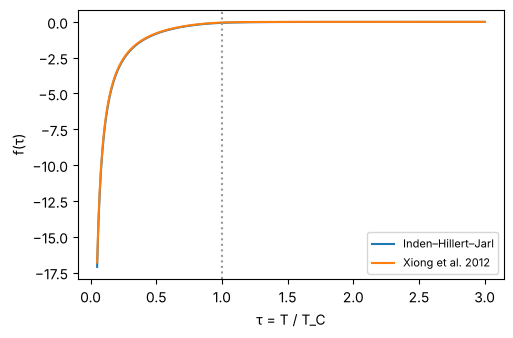

f just below and above τ = 1 (Xiong): -0.046007949, -0.046007936


In [7]:
taus = np.linspace(0.05, 3.0, 600)
beta = np.e - 1
ihj_mag, x_mag = Magnetic(afm=-1.0, p=0.4), Magnetic(afm=0.0, p=0.4)
f_ihj = [float(ihj(ihj_mag, 1.0, beta, t, NUM)) for t in taus]
f_x = [float(xiong(x_mag, 1.0, 0.0, beta, t, NUM)) for t in taus]
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(taus, f_ihj, label="Inden–Hillert–Jarl")
ax.plot(taus, f_x, label="Xiong et al. 2012")
ax.axvline(1, color="0.6", ls=":")
ax.set_xlabel("τ = T / T_C")
ax.set_ylabel("f(τ)")
ax.legend(fontsize=8)
plt.show()
print(
    f"f just below and above τ = 1 (Xiong): {float(xiong(x_mag, 1.0, 0.0, beta, 1 - 1e-9, NUM)):.9f}, "
    f"{float(xiong(x_mag, 1.0, 0.0, beta, 1 + 1e-9, NUM)):.9f}"
)

Notebook 05 uses the Xiong model in the Fe–Mn liquid, together with the
Einstein and two-state terms.